In [1]:
import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline

#Two lines Required to Plot Plotly
import plotly.io as pio
pio.renderers.default = 'iframe'

import plotly.graph_objs as go
import plotly.offline as py
import plotly.express as px

#Ignore warnings
import warnings
warnings.filterwarnings('ignore')

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory
'''
import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))
'''
# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

"\nimport os\nfor dirname, _, filenames in os.walk('/kaggle/input'):\n    for filename in filenames:\n        print(os.path.join(dirname, filename))\n"

In [2]:
import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline

#Ignore warnings
import warnings
warnings.filterwarnings('ignore')

### Udacity Self-Driving Car Obstacles Dataset

Dataset's author: Barkar Ali Arbab

"The Udacity Self-Driving Car Dataset (fixed-small) is a publicly available computer vision dataset designed for obstacle detection in autonomous driving scenarios. It contains 15,000 annotated images capturing real-world road environments, with labels focused on identifying obstacles relevant to self-driving applications. The dataset was exported on February 11, 2020, and has been widely used for training and benchmarking object detection models."

https://www.kaggle.com/datasets/barkataliarbab/udacity-self-driving-car-obstacles-dataset/data

In [3]:
%pip install -q ultralytics "opencv-python<4.11"

Note: you may need to restart the kernel to use updated packages.


In [4]:
import cv2
import shutil
import glob
from pathlib import Path
import random
from sklearn.model_selection import train_test_split
from ultralytics import YOLO
import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings('ignore')

## Images sample

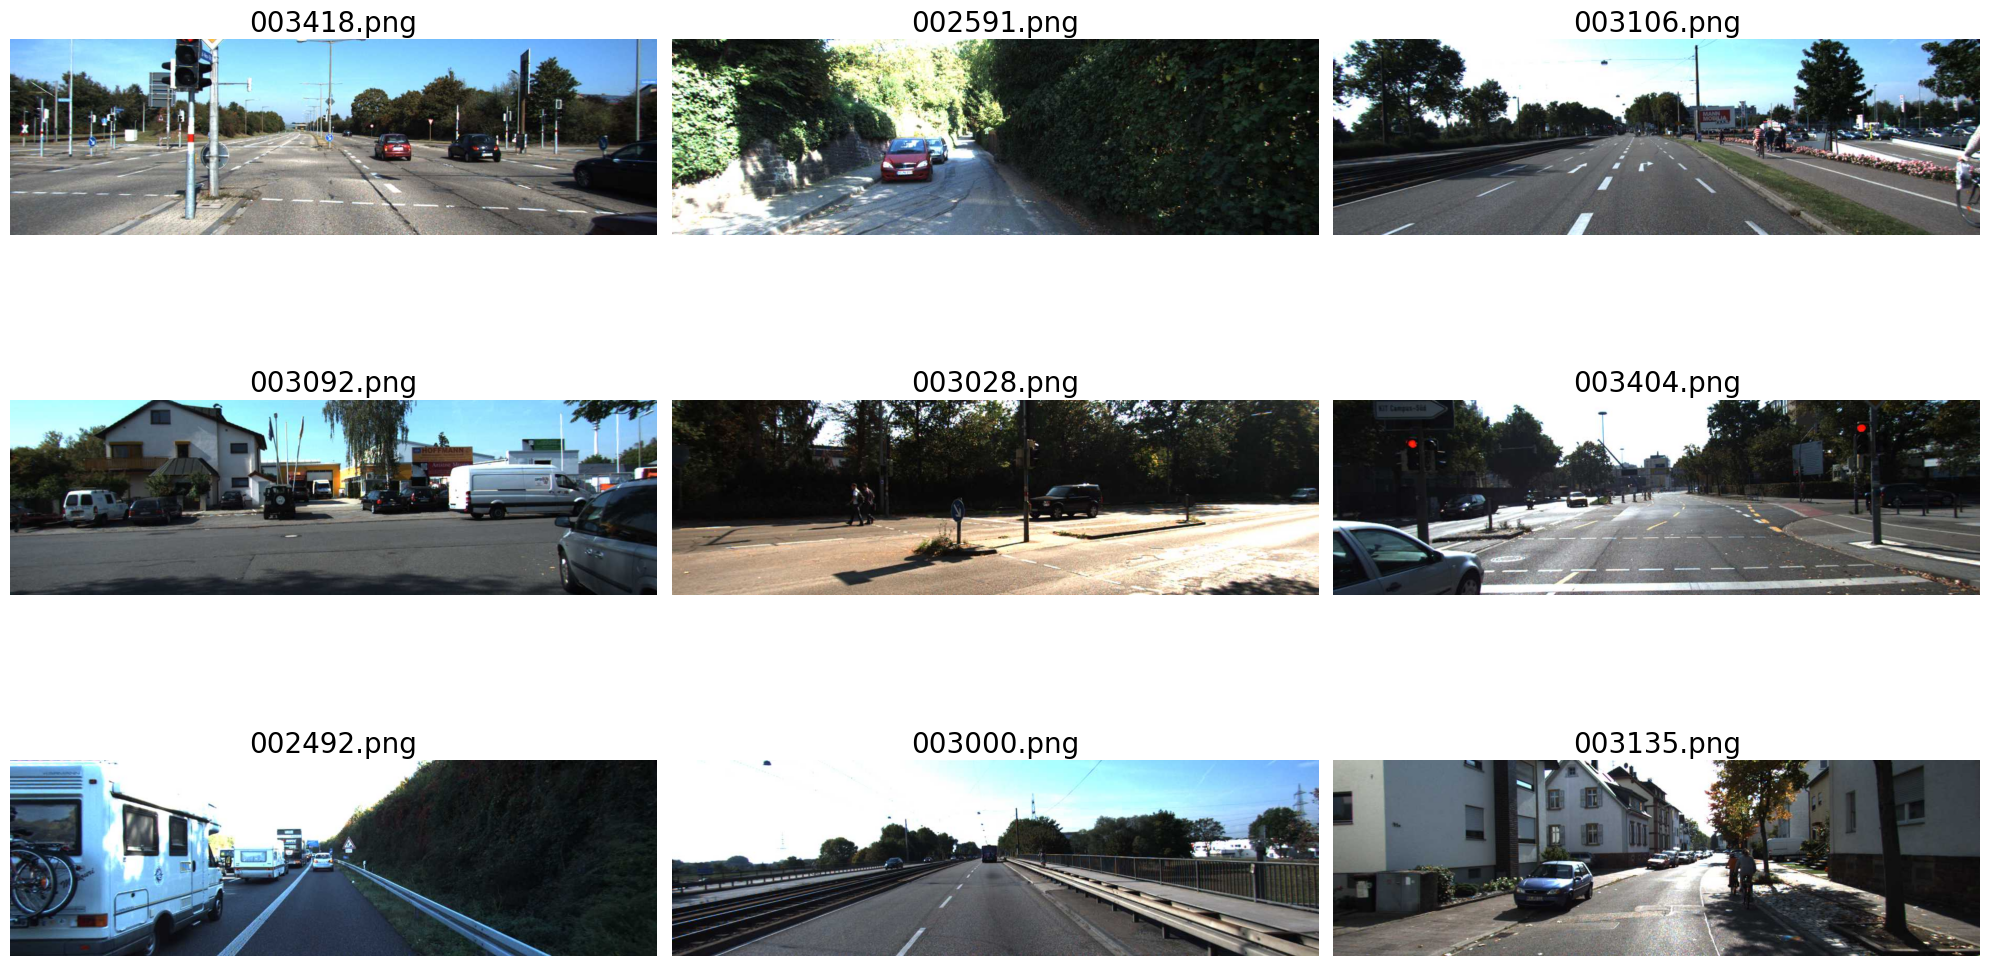

In [5]:
train_images_dir = Path(r"C:\Users\Ayan\Desktop\YOLO THESIS PROJECT\Self-Driving Car Obstacles Yolo attempt kitti\kitti\images")

image_files = list(train_images_dir.glob("*.png"))

sample_files = random.sample(image_files, min(9, len(image_files)))

fig, axes = plt.subplots(3, 3, figsize=(20, 12))
axes = axes.flatten()

for ax, img_path in zip(axes, sample_files):
    img = cv2.imread(str(img_path))                  
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)       
    ax.imshow(img)
    ax.axis("off")
    ax.set_title(img_path.name, fontsize=20)

plt.tight_layout()
plt.show()

In [6]:
from pathlib import Path

PATH_DATA = r"C:\Users\Ayan\Desktop\YOLO THESIS PROJECT\Self-Driving Car Obstacles Yolo attempt kitti"
PATH_DATASET = Path(PATH_DATA) / "kitti"

In [7]:
# Assuming the images and annotations are in subdirectories like 'images' and 'labels'
# within the downloaded dataset path.
image_files = glob.glob(str(PATH_DATASET / 'images/*.png'), recursive=True)
label_files = glob.glob(str(PATH_DATASET / 'labels/*.txt'), recursive=True)

# Create a list of tuples (image_path, label_path)
image_annotation_pairs = []
for img_path in image_files:
    # Construct the corresponding label file path by replacing 'images' with 'labels' and changing the extension to '.txt'
    label_path = Path(str(img_path).replace('images', 'labels')).with_suffix('.txt')
    if label_path.exists():
        image_annotation_pairs.append((img_path, str(label_path)))

print(f"Found {len(image_annotation_pairs)} image and annotation pairs.")

# Print the first few pairs as examples
print("\nSample image and annotation pairs:")
for img_path, label_path in image_annotation_pairs[:5]:
    print(f"Image: {img_path}, Annotation: {label_path}")

Found 954 image and annotation pairs.

Sample image and annotation pairs:
Image: C:\Users\Ayan\Desktop\YOLO THESIS PROJECT\Self-Driving Car Obstacles Yolo attempt kitti\kitti\images\002375.png, Annotation: C:\Users\Ayan\Desktop\YOLO THESIS PROJECT\Self-Driving Car Obstacles Yolo attempt kitti\kitti\labels\002375.txt
Image: C:\Users\Ayan\Desktop\YOLO THESIS PROJECT\Self-Driving Car Obstacles Yolo attempt kitti\kitti\images\002376.png, Annotation: C:\Users\Ayan\Desktop\YOLO THESIS PROJECT\Self-Driving Car Obstacles Yolo attempt kitti\kitti\labels\002376.txt
Image: C:\Users\Ayan\Desktop\YOLO THESIS PROJECT\Self-Driving Car Obstacles Yolo attempt kitti\kitti\images\002377.png, Annotation: C:\Users\Ayan\Desktop\YOLO THESIS PROJECT\Self-Driving Car Obstacles Yolo attempt kitti\kitti\labels\002377.txt
Image: C:\Users\Ayan\Desktop\YOLO THESIS PROJECT\Self-Driving Car Obstacles Yolo attempt kitti\kitti\images\002378.png, Annotation: C:\Users\Ayan\Desktop\YOLO THESIS PROJECT\Self-Driving Car Obs


DATA SPLITTING CODE - ADD THIS AFTER image_annotation_pairs


In [ ]:
# ====================================================================
# FIXED DATA SPLITTING CODE - ADD THIS AFTER image_annotation_pairs
# ====================================================================

from sklearn.model_selection import train_test_split
import shutil

# Split data into train and validation sets (80% train, 20% validation)
train_pairs, val_pairs = train_test_split(
    image_annotation_pairs,
    test_size=0.2,  # 20% for validation
    random_state=42,  # For reproducibility
    shuffle=True  # Shuffle the data before splitting
)

print(f"\n=== Data Split Results ===")
print(f"Training samples: {len(train_pairs)}")
print(f"Validation samples: {len(val_pairs)}")
print(f"Train/Val ratio: {len(train_pairs)/len(image_annotation_pairs):.1%}/{len(val_pairs)/len(image_annotation_pairs):.1%}")

# Create separate directories for train and val splits
def create_split_directories(pairs, split_name):
    """
    Create directory structure for a split (train or val)
    and copy the image/label files to appropriate locations
    """
    # Create split directories
    split_dir = PATH_DATASET / split_name
    images_dir = split_dir / 'images'
    labels_dir = split_dir / 'labels'
    
    images_dir.mkdir(parents=True, exist_ok=True)
    labels_dir.mkdir(parents=True, exist_ok=True)
    
    # Copy files
    for img_path, label_path in pairs:
        # Copy image
        img_filename = Path(img_path).name
        dst_img_path = images_dir / img_filename
        shutil.copy2(img_path, dst_img_path)
        
        # Copy label
        label_filename = Path(label_path).name
        dst_label_path = labels_dir / label_filename
        shutil.copy2(label_path, dst_label_path)
    
    print(f"Created {split_name} directory with {len(pairs)} samples")
    print(f"  Images: {images_dir}")
    print(f"  Labels: {labels_dir}")
    
    return split_dir

# Create train and validation directories
print("\n=== Creating split directories ===")
train_dir = create_split_directories(train_pairs, 'train')
val_dir = create_split_directories(val_pairs, 'val')

## Load and parse data

Read the image and annotation files from the image_annotation_pairs list. Parse the YOLO format annotations to get the bounding box coordinates and class labels.

By Jirka Borovec https://www.kaggle.com/code/jirkaborovec/cctv-weapon-train-yolo-detection/notebook

Parsing that **takes a lot of time**

In [8]:
# List to store the parsed data
parsed_data = []

for img_path, label_path in image_annotation_pairs:
    # Read the image
    image = cv2.imread(img_path)
    if image is None:
        print(f"Warning: Could not read image {img_path}")
        continue

    height, width, _ = image.shape

    # Read the annotation file
    annotations = []
    with open(label_path, 'r') as f:
        for line in f:
            parts = line.strip().split()
            if len(parts) == 5:
                class_id = int(parts[0])
                # YOLO format: center_x, center_y, width, height (normalized)
                center_x, center_y, bbox_width_norm, bbox_height_norm = map(float, parts[1:])

                # Convert normalized coordinates to absolute pixel coordinates (top-left x, top-left y, width, height)
                bbox_width_abs = bbox_width_norm * width
                bbox_height_abs = bbox_height_norm * height
                top_left_x = (center_x * width) - (bbox_width_abs / 2)
                top_left_y = (center_y * height) - (bbox_height_abs / 2)

                annotations.append({
                    'class_id': class_id,
                    'bbox': (int(top_left_x), int(top_left_y), int(bbox_width_abs), int(bbox_height_abs))
                })
            else:
                print(f"Warning: Skipping invalid line in {label_path}: {line.strip()}")

    parsed_data.append({
        'image': image,  # THIS STORES FULL IMAGES - MEMORY EXPLOSION!
        'annotations': annotations,
        'image_path': img_path
    })

print(f"Successfully parsed annotations for {len(parsed_data)} images.")

KeyboardInterrupt: 

## Visualize images with annotations

Display a grid of images with the parsed bounding boxes and labels drawn on them.

In [ ]:
import yaml

class_names = ['car', 'van', 'truck', 'pedestrian', 'person_sitting', 'cyclist', 'tram', 'misc']

# Define colors for ALL 11 classes based on your dataset
class_colors = {
    0: 'yellow',        # biker
    1: 'red',           # car
    2: 'green',         # pedestrian
    3: 'cyan',          # trafficLight
    4: 'lime',          # trafficLight-Green
    5: 'darkgreen',     # trafficLight-GreenLeft
    6: 'darkred',       # trafficLight-Red
    7: 'maroon',        # trafficLight-RedLeft
}

# Create a Python dictionary containing the dataset information.
dataset_info = {
    'path': str(PATH_DATASET),  # Base path to the dataset directory
    'train': 'train/images',    # Relative path to training images
    'val': 'val/images',        # Relative path to validation images
    'nc': len(class_names),     # Number of classes
    'names': class_names        # List of class names
}

# Define the filename for the YAML file
yaml_filename = 'data.yaml'

# Open the specified filename in write mode ('w') and Use a YAML library to dump the dictionary
with open(yaml_filename, 'w') as f:
    yaml.dump(dataset_info, f, default_flow_style=None)

# Print a confirmation message
print(f"Dataset YAML file '{yaml_filename}' created successfully.")
print(f"Training path: {dataset_info['train']}")
print(f"Validation path: {dataset_info['val']}")

In [ ]:
import matplotlib.patches as patches

# Define the number of images to display and the grid layout
n_images_to_display = 9  # Display the first 9 images
n_cols = 3
n_rows = (n_images_to_display + n_cols - 1) // n_cols # Calculate rows needed
# Create a figure and a set of subplots
fig, axes = plt.subplots(n_rows, n_cols, figsize=(15, n_rows * 5))
# Flatten the axes array for easy iteration
axes = axes.flatten()

# Iterate through the first n_images_to_display items in the parsed_data list
for i in range(min(n_images_to_display, len(parsed_data))):
    data = parsed_data[i]
    image = data['image']
    annotations = data['annotations']

    # Convert the image from BGR to RGB for displaying with matplotlib
    image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

    # Display the image
    axes[i].imshow(image_rgb)
    axes[i].set_title(f"Image {i+1}")
    axes[i].axis('off')

    # Draw bounding boxes and labels
    for annotation in annotations:
        class_id = annotation['class_id']
        x, y, w, h = annotation['bbox']
        # Get the color for the current class, default to a color if not in class_colors
        color = class_colors.get(class_id, 'red') # Use blue for other classes
        # Create a Rectangle patch
        rect = patches.Rectangle((x, y), w, h, linewidth=1, edgecolor=color, facecolor='none')
        # Add the patch to the Axes
        axes[i].add_patch(rect)
        # Add class ID as text
        axes[i].text(x, y - 10, f'Class: {class_id}', color=color, fontsize=8, bbox=dict(facecolor='white', alpha=0.5))

# Hide any unused subplots
for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

## These were found on the data.yaml file

'biker', 'car', 'pedestrian', 'trafficLight', 'trafficLight-Green', 'trafficLight-GreenLeft', 'trafficLight-Red', 'trafficLight-RedLeft', 'trafficLight-Yellow', 'trafficLight-YellowLeft', 'truck'

## Create yaml file

Generate the dataset.yaml file with the defined paths and class names in the required YOLO format.

Define the class names based on the dataset's content. From the previous visualization, we saw class_id 0 and 1. We need to determine what these class IDs represent. Without explicit class mapping information, we will make an educated guess or use generic names. A common convention for weapon detection might be something like 'gun' or 'weapon'. Let's assume class 0 is 'weapon' and class 1 is 'person' (or vice versa), or just generic names. Since the dataset is "cctv-weapon-dataset", class 0 is likely 'weapon'. We need to be careful if there are other classes. Based on the visualization showing class_id 0 and 1, let's assume there are two classes. We'll need to confirm the actual class names if possible.

Let's assume based on the dataset name and common object detection classes:

Class 0: 'car' Class 1: 'obstacle' # Assuming class 0 is 'car' and class 1 is 'obstacle'

In [ ]:
import yaml

class_names = ['car', 'van', 'truck', 'pedestrian', 'person_sitting', 'cyclist', 'tram', 'misc']

# Define colors for ALL 11 classes based on your dataset
class_colors = {
    0: 'yellow',        # biker
    1: 'red',           # car
    2: 'green',         # pedestrian
    3: 'cyan',          # trafficLight
    4: 'lime',          # trafficLight-Green
    5: 'darkgreen',     # trafficLight-GreenLeft
    6: 'darkred',       # trafficLight-Red
    7: 'maroon',        # trafficLight-RedLeft
}

# Create a Python dictionary containing the dataset information.
dataset_info = {
    'path': str(PATH_DATASET),  # Base path to the dataset directory
    'train': 'train/images',    # Relative path to training images
    'val': 'val/images',        # Relative path to validation images
    'nc': len(class_names),     # Number of classes
    'names': class_names        # List of class names
}

# Define the filename for the YAML file
yaml_filename = 'data.yaml'

# Open the specified filename in write mode ('w') and Use a YAML library to dump the dictionary
with open(yaml_filename, 'w') as f:
    yaml.dump(dataset_info, f, default_flow_style=None)

# Print a confirmation message
print(f"Dataset YAML file '{yaml_filename}' created successfully.")
print(f"Training path: {dataset_info['train']}")
print(f"Validation path: {dataset_info['val']}")

## Train YOLO Model

This cell uses the Ultralytics library to train a YOLO object detection model on your dataset.

It first loads a pretrained yolov8s.pt model. Then, it starts the training process using the model.train() method. data='dataset.yaml' specifies the path to the dataset configuration file we created. epochs=10 sets the number of training iterations. imgsz=640 sets the input image size for training. The training results will be saved in the runs/detect/train directory by default.

In [9]:
import os
os.path.getsize("yolo11m.pt")


40684120

In [6]:
from ultralytics import YOLO

# Load a pretrained YOLOv8s model
# You can choose other models like 'yolov8n.pt', 'yolov8m.pt', etc.
model = YOLO(r"C:\Users\Ayan\Desktop\YOLO THESIS PROJECT\Self-Driving Car Obstacles Yolo attempt kitti\runs\detect\TRAINING\50epochs\weights\best.pt")

## Epochs! More memory. Notebook was restarted. 

Your notebook tried to allocate more memory than is available. It has restarted.

Epochs original 100!!!!! I changed to 10 (ten Only)

Message: More memory than avaiable. Notebook was restarted.

Then, I tried one ridiculous single Epoch. and didn't work too.

In [8]:
# Train the model on the dataset
# 'data' specifies the path to your dataset.yaml file
# 'epochs' sets the number of training epochs
# 'imgsz' sets the image size
from ultralytics import YOLO


results = model.train(
    data='data.yaml',
    epochs=50,           # Train 30 more epochs
    imgsz=640,           # Smaller for speed
    batch=6,
    device=0,
    lr0=0.000001,          # Low learning rate
    patience=20,
    name='50epochs'
)

print("Training continued successfully!")

New https://pypi.org/project/ultralytics/8.4.3 available  Update with 'pip install -U ultralytics'
Ultralytics 8.3.253  Python-3.12.0 torch-2.5.1+cu121 CUDA:0 (NVIDIA GeForce RTX 4050 Laptop GPU, 6140MiB)
engine\trainer: agnostic_nms=False, amp=True, augment=False, auto_augment=randaugment, batch=6, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=1e-06, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=C:\Users\Ayan\Desktop\YOLO THESIS PROJECT\Self-Driving Car Obstacles Yolo attempt kitti\runs\detect\TR

### Your notebook tried to allocate more memory than is available. It has restarted.

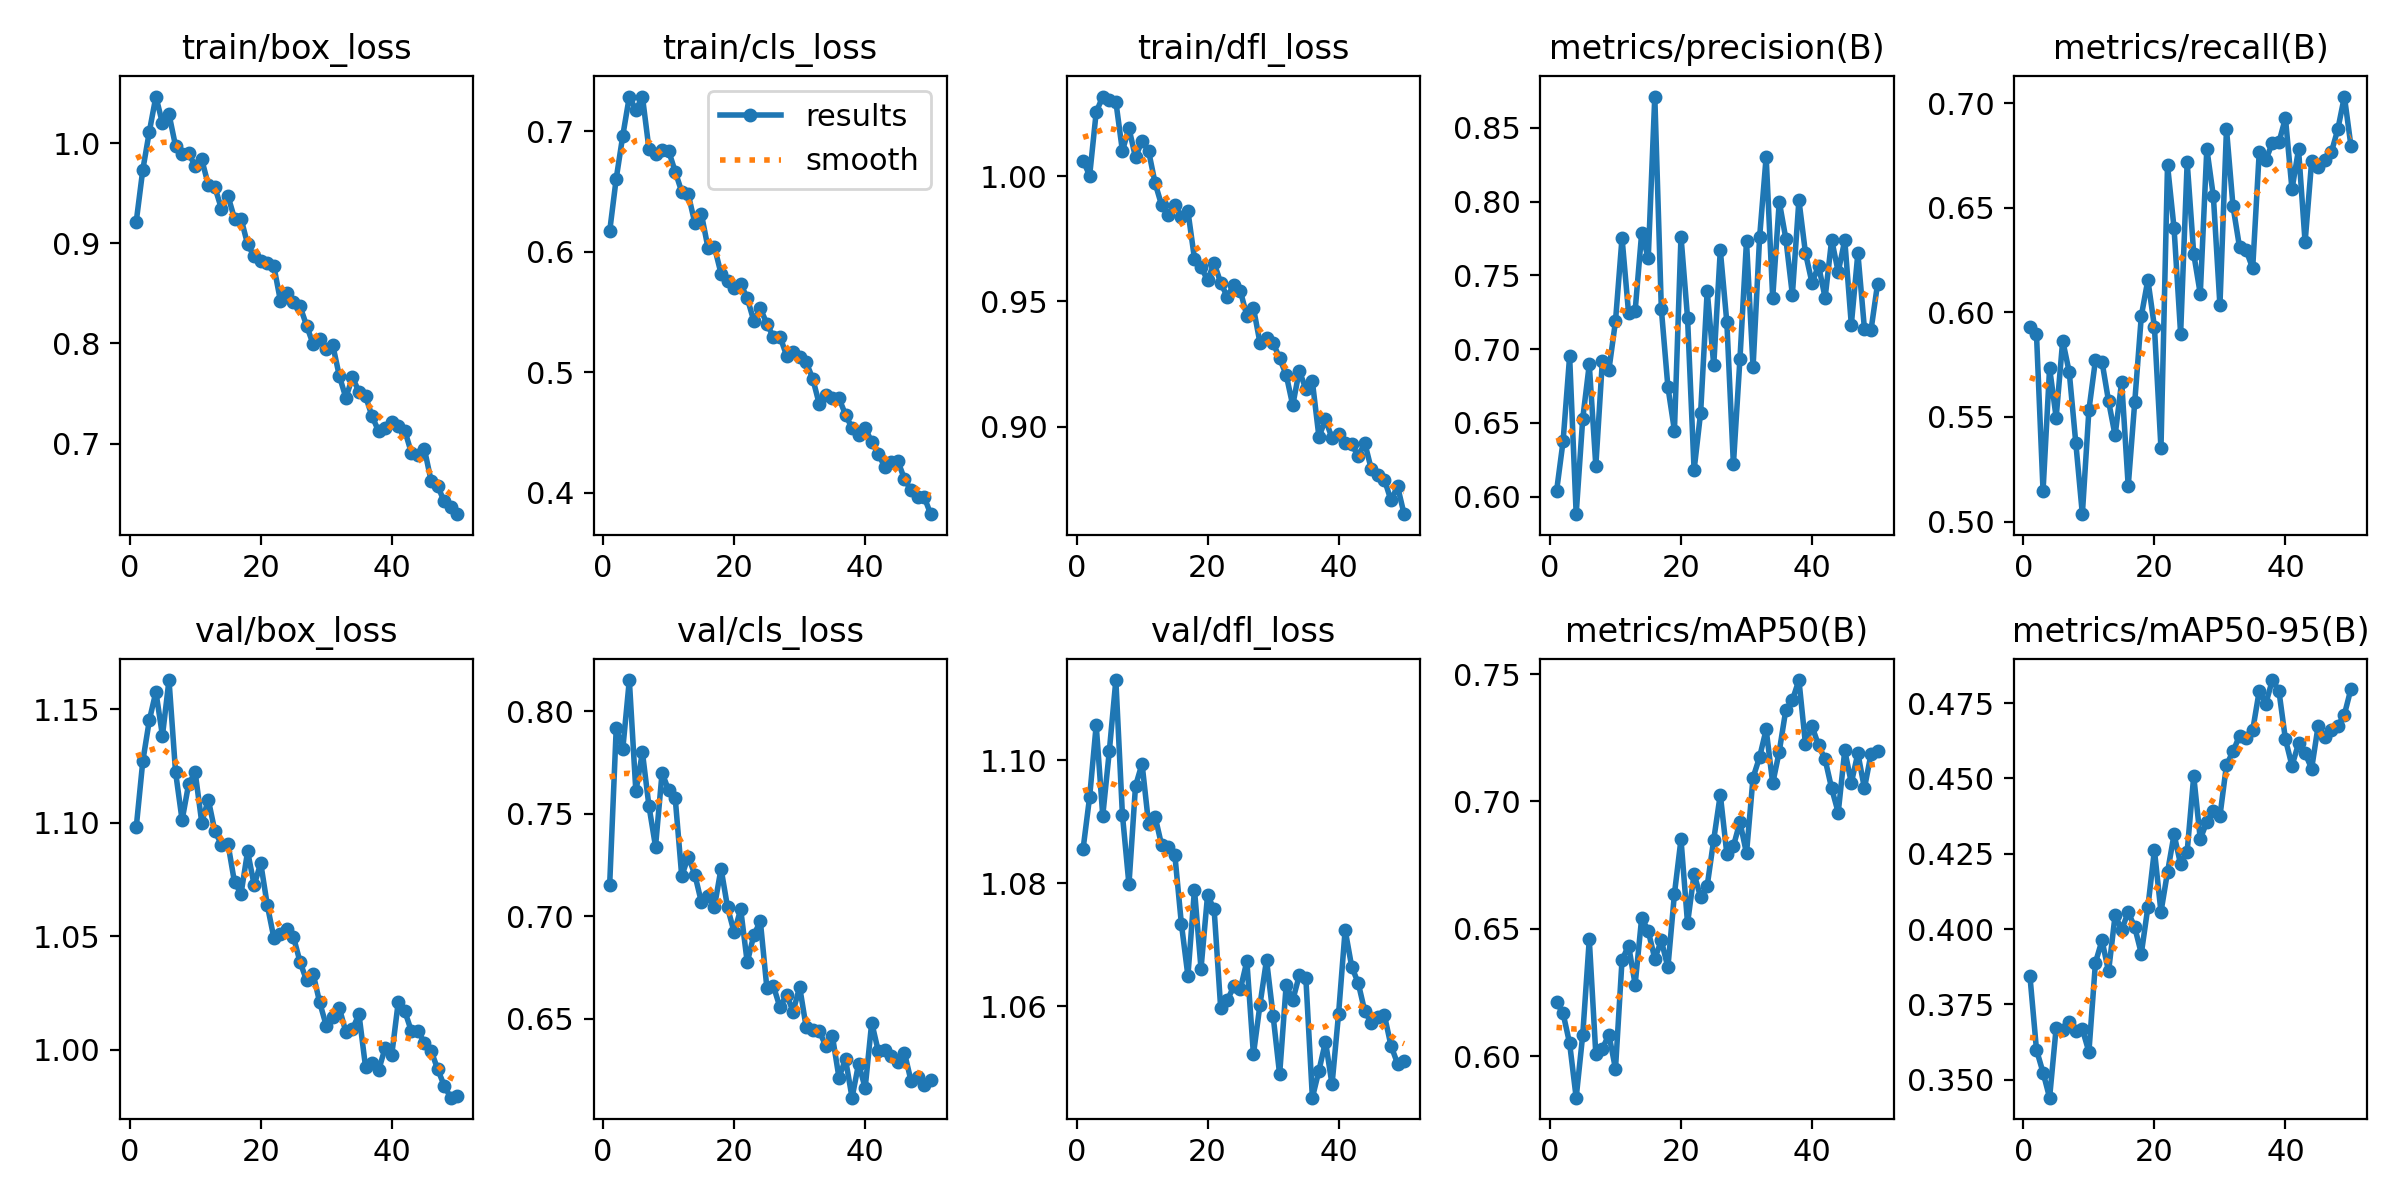

In [9]:
import os
import glob
from IPython.display import Image, display

# Base directory for training runs
runs_dir = r"C:\Users\Ayan\Desktop\YOLO THESIS PROJECT\Self-Driving Car Obstacles Yolo attempt kitti\runs\detect"

# Find the latest training run folder matching '50epochs*'
latest_run_dir = max(glob.glob(os.path.join(runs_dir, '50epochs*')), key=os.path.getctime)

# Path to the results plot
results_plot_path = os.path.join(latest_run_dir, 'results.png')

# Display the image
display(Image(filename=results_plot_path))


In [10]:
# You can also run validation after training
model = YOLO(r"C:\Users\Ayan\Desktop\YOLO THESIS PROJECT\Self-Driving Car Obstacles Yolo attempt kitti\runs\detect\50epochs\weights\best.pt")
results = model.val()

# Display key validation metrics in a human-readable format
print("\nValidation Metrics:")
print(f"  mAP50-95: {results.box.map:.4f}")
print(f"  mAP50: {results.box.map50:.4f}")
print(f"  Precision: {results.box.p.mean():.4f}")
print(f"  Recall: {results.box.r.mean():.4f}")

# Print metrics per class if available
if results.box.ap_class_index is not None and results.box.ap is not None:
    print("\nMetrics per Class:")
    for i, class_index in enumerate(results.box.ap_class_index):
        class_name = model.names[class_index]
        print(f"  Class '{class_name}' (ID {class_index}):")
        print(f"    AP50-95: {results.box.ap[i]:.4f}")
        print(f"    AP50: {results.box.ap50[i]:.4f}")
        print(f"    Precision: {results.box.p[i]:.4f}")
        print(f"    Recall: {results.box.r[i]:.4f}")

Ultralytics 8.3.253  Python-3.12.0 torch-2.5.1+cu121 CUDA:0 (NVIDIA GeForce RTX 4050 Laptop GPU, 6140MiB)
YOLO11m summary (fused): 125 layers, 20,036,200 parameters, 0 gradients, 67.7 GFLOPs
val: Fast image access  (ping: 0.00.0 ms, read: 638.6146.1 MB/s, size: 53.8 KB)
val: Scanning C:\Users\Ayan\Desktop\YOLO THESIS PROJECT\Self-Driving Car Obstacles Yolo attempt kitti\kitti\val\labels.cache... 191 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 191/191  0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 12/12 6.8it/s 1.8s0.1s
                   all        191       1073        0.8      0.682      0.749      0.485
                   car        171        758      0.862      0.877      0.922      0.703
                   van         50         64      0.778      0.703      0.768      0.592
                 truck         27         27      0.719      0.778      0.847      0.619
            pedestrian         54        132

In [1]:
from ultralytics import YOLO

# Load YOLOv8 medium model
model = YOLO('yolov8m.pt')  # if the file is not present, it will download automatically

In [2]:
# Train the model on the dataset
# 'data' specifies the path to your dataset.yaml file
# 'epochs' sets the number of training epochs
# 'imgsz' sets the image size
from ultralytics import YOLO


results = model.train(
    data='data.yaml',
    epochs=30,           # Train 30 more epochs
    imgsz=640,           # Smaller for speed
    batch=6,
    device=0,
    lr0=0.000001,          # Low learning rate
    patience=20,
    name='30epochs'
)

print("Training continued successfully!")

New https://pypi.org/project/ultralytics/8.4.3 available  Update with 'pip install -U ultralytics'
Ultralytics 8.3.253  Python-3.12.0 torch-2.5.1+cu121 CUDA:0 (NVIDIA GeForce RTX 4050 Laptop GPU, 6140MiB)
engine\trainer: agnostic_nms=False, amp=True, augment=False, auto_augment=randaugment, batch=6, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=30, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=1e-06, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8m.pt, momentum=0.937, mosaic=1.0, multi_scale=False, name=30epochs, nbs=64, nms=False, opset=Non

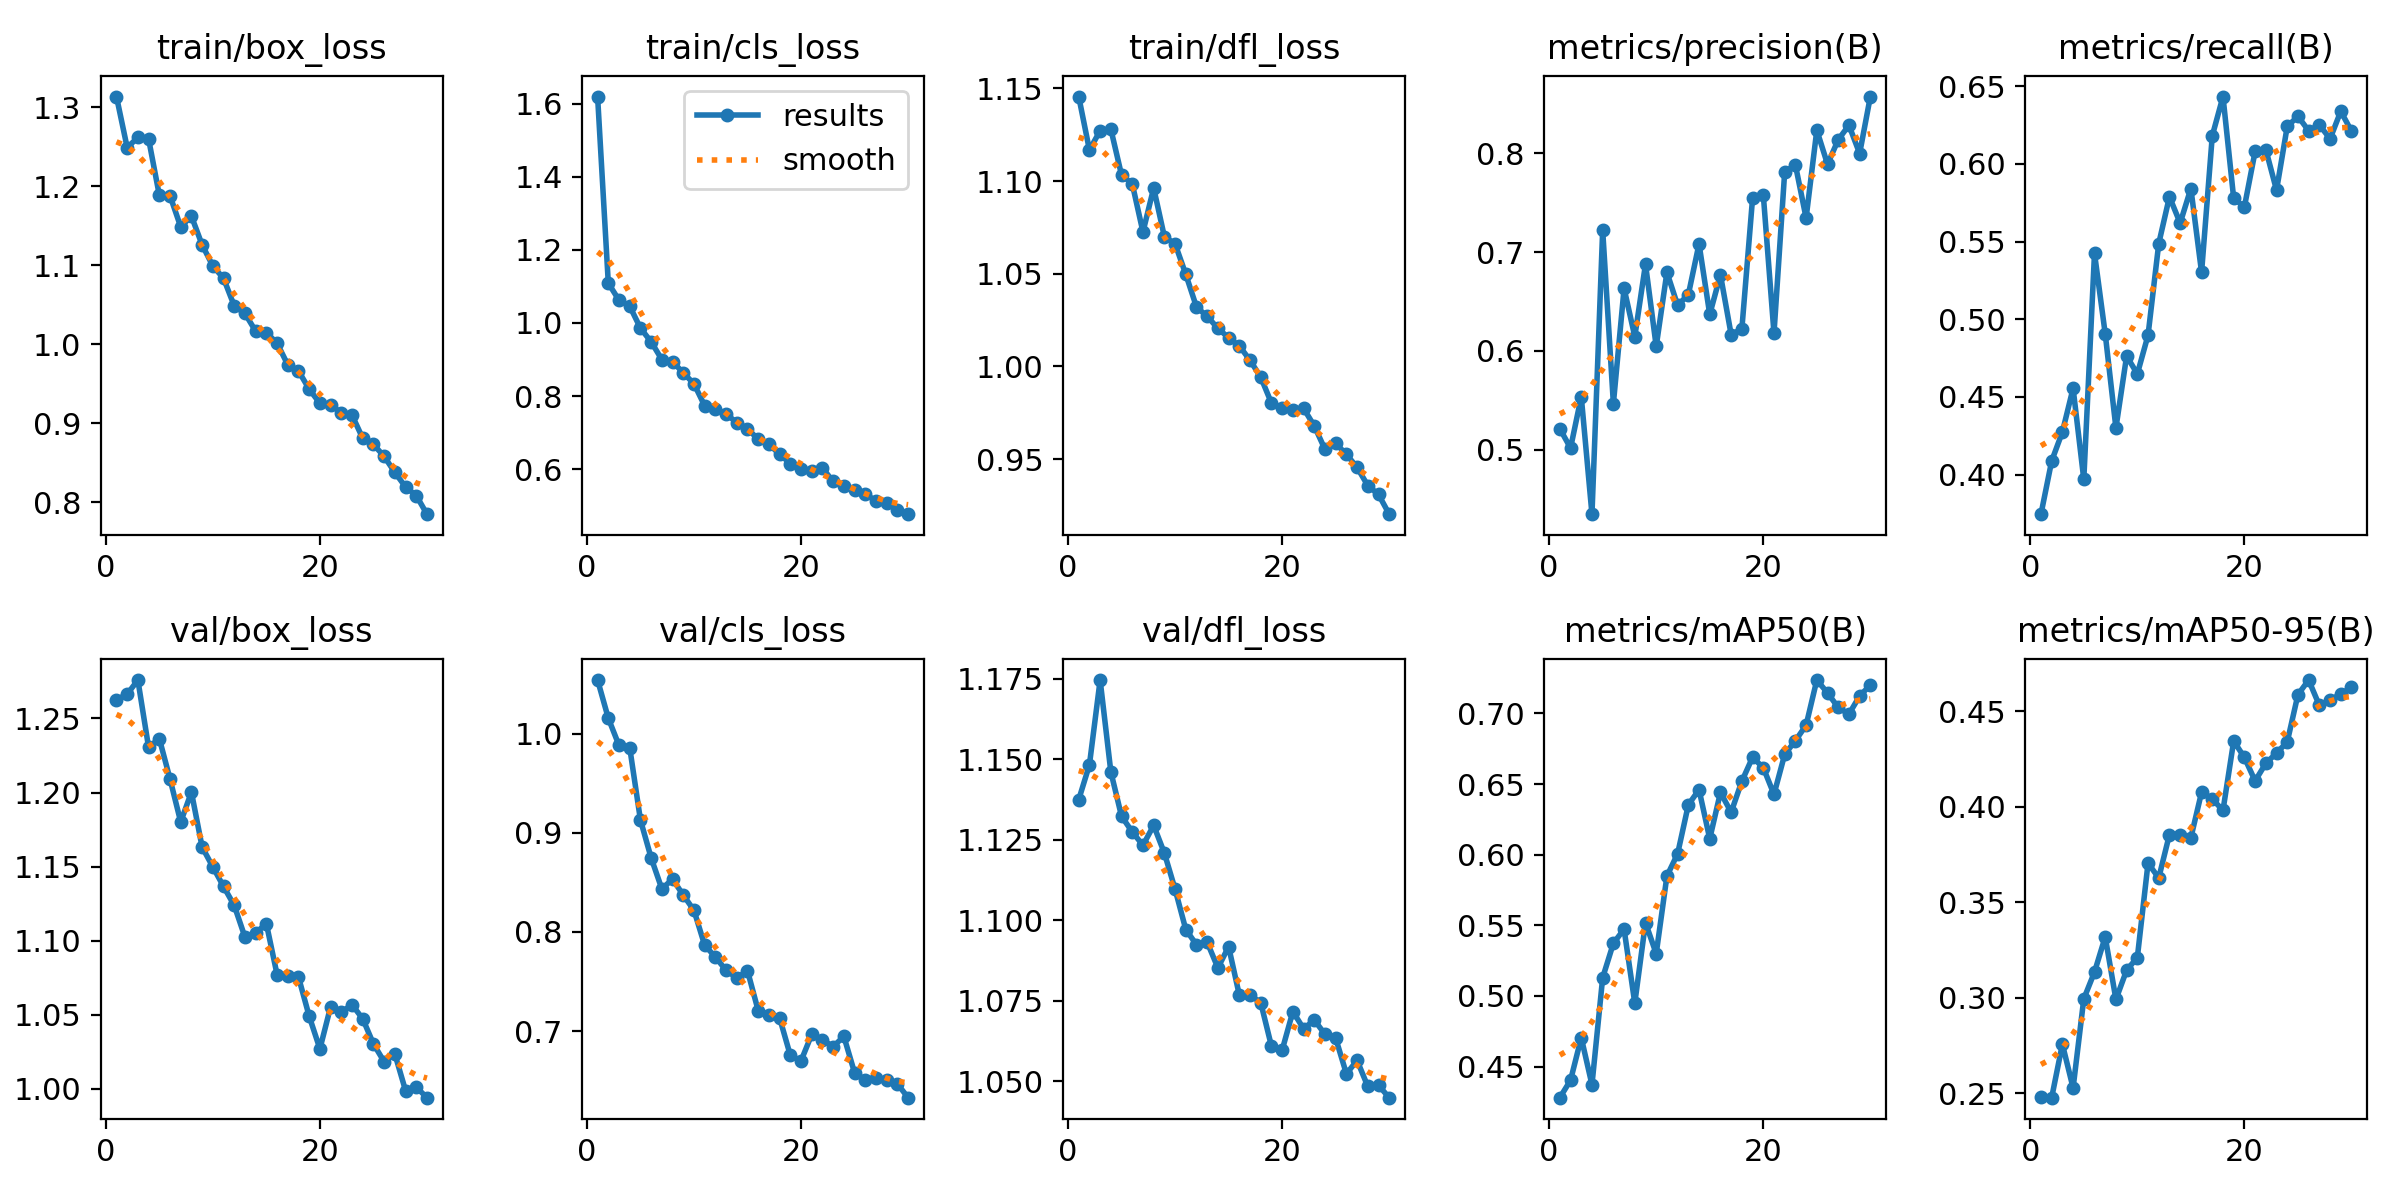

In [ ]:
import os
import glob
from IPython.display import Image, display

# Base directory for training runs
runs_dir = r"C:\Users\Ayan\Desktop\YOLO THESIS PROJECT\Self-Driving Car Obstacles Yolo attempt kitti\runs\detect"

# Find the latest training run folder matching '50epochs*'
latest_run_dir = max(glob.glob(os.path.join(runs_dir, '0epochs*')), key=os.path.getctime)

# Path to the results plot
results_plot_path = os.path.join(latest_run_dir, 'results.png')

# Display the image
display(Image(filename=results_plot_path))


In [4]:
# You can also run validation after training
model = YOLO(r"C:\Users\Ayan\Desktop\YOLO THESIS PROJECT\Self-Driving Car Obstacles Yolo attempt kitti\runs\detect\30epochs\weights\best.pt")
results = model.val()

# Display key validation metrics in a human-readable format
print("\nValidation Metrics:")
print(f"  mAP50-95: {results.box.map:.4f}")
print(f"  mAP50: {results.box.map50:.4f}")
print(f"  Precision: {results.box.p.mean():.4f}")
print(f"  Recall: {results.box.r.mean():.4f}")

# Print metrics per class if available
if results.box.ap_class_index is not None and results.box.ap is not None:
    print("\nMetrics per Class:")
    for i, class_index in enumerate(results.box.ap_class_index):
        class_name = model.names[class_index]
        print(f"  Class '{class_name}' (ID {class_index}):")
        print(f"    AP50-95: {results.box.ap[i]:.4f}")
        print(f"    AP50: {results.box.ap50[i]:.4f}")
        print(f"    Precision: {results.box.p[i]:.4f}")
        print(f"    Recall: {results.box.r[i]:.4f}")

Ultralytics 8.3.253  Python-3.12.0 torch-2.5.1+cu121 CUDA:0 (NVIDIA GeForce RTX 4050 Laptop GPU, 6140MiB)
Model summary (fused): 92 layers, 25,844,392 parameters, 0 gradients, 78.7 GFLOPs
val: Fast image access  (ping: 0.00.0 ms, read: 508.067.3 MB/s, size: 52.6 KB)
val: Scanning C:\Users\Ayan\Desktop\YOLO THESIS PROJECT\Self-Driving Car Obstacles Yolo attempt kitti\kitti\val\labels.cache... 191 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 191/191  0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 12/12 6.8it/s 1.8s0.1s
                   all        191       1073       0.79      0.622      0.719      0.469
                   car        171        758      0.893      0.839       0.91      0.676
                   van         50         64      0.695      0.641      0.729      0.523
                 truck         27         27      0.778      0.741      0.862      0.666
            pedestrian         54        132    

In [5]:
from ultralytics import YOLO

# Load YOLOv8 medium model
model = YOLO(r"C:\Users\Ayan\Desktop\YOLO THESIS PROJECT\Self-Driving Car Obstacles Yolo attempt kitti\runs\detect\30epochs\weights\best.pt")  # if the file is not present, it will download automatically

In [6]:
# Train the model on the dataset
# 'data' specifies the path to your dataset.yaml file
# 'epochs' sets the number of training epochs
# 'imgsz' sets the image size
from ultralytics import YOLO


results = model.train(
    data='data.yaml',
    epochs=50,           # Train 30 more epochs
    imgsz=640,           # Smaller for speed
    batch=6,
    device=0,
    lr0=0.000001,          # Low learning rate
    patience=20,
    name='50epochs'
)

print("Training continued successfully!")

New https://pypi.org/project/ultralytics/8.4.3 available  Update with 'pip install -U ultralytics'
Ultralytics 8.3.253  Python-3.12.0 torch-2.5.1+cu121 CUDA:0 (NVIDIA GeForce RTX 4050 Laptop GPU, 6140MiB)
engine\trainer: agnostic_nms=False, amp=True, augment=False, auto_augment=randaugment, batch=6, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=1e-06, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=C:\Users\Ayan\Desktop\YOLO THESIS PROJECT\Self-Driving Car Obstacles Yolo attempt kitti\runs\detect\30

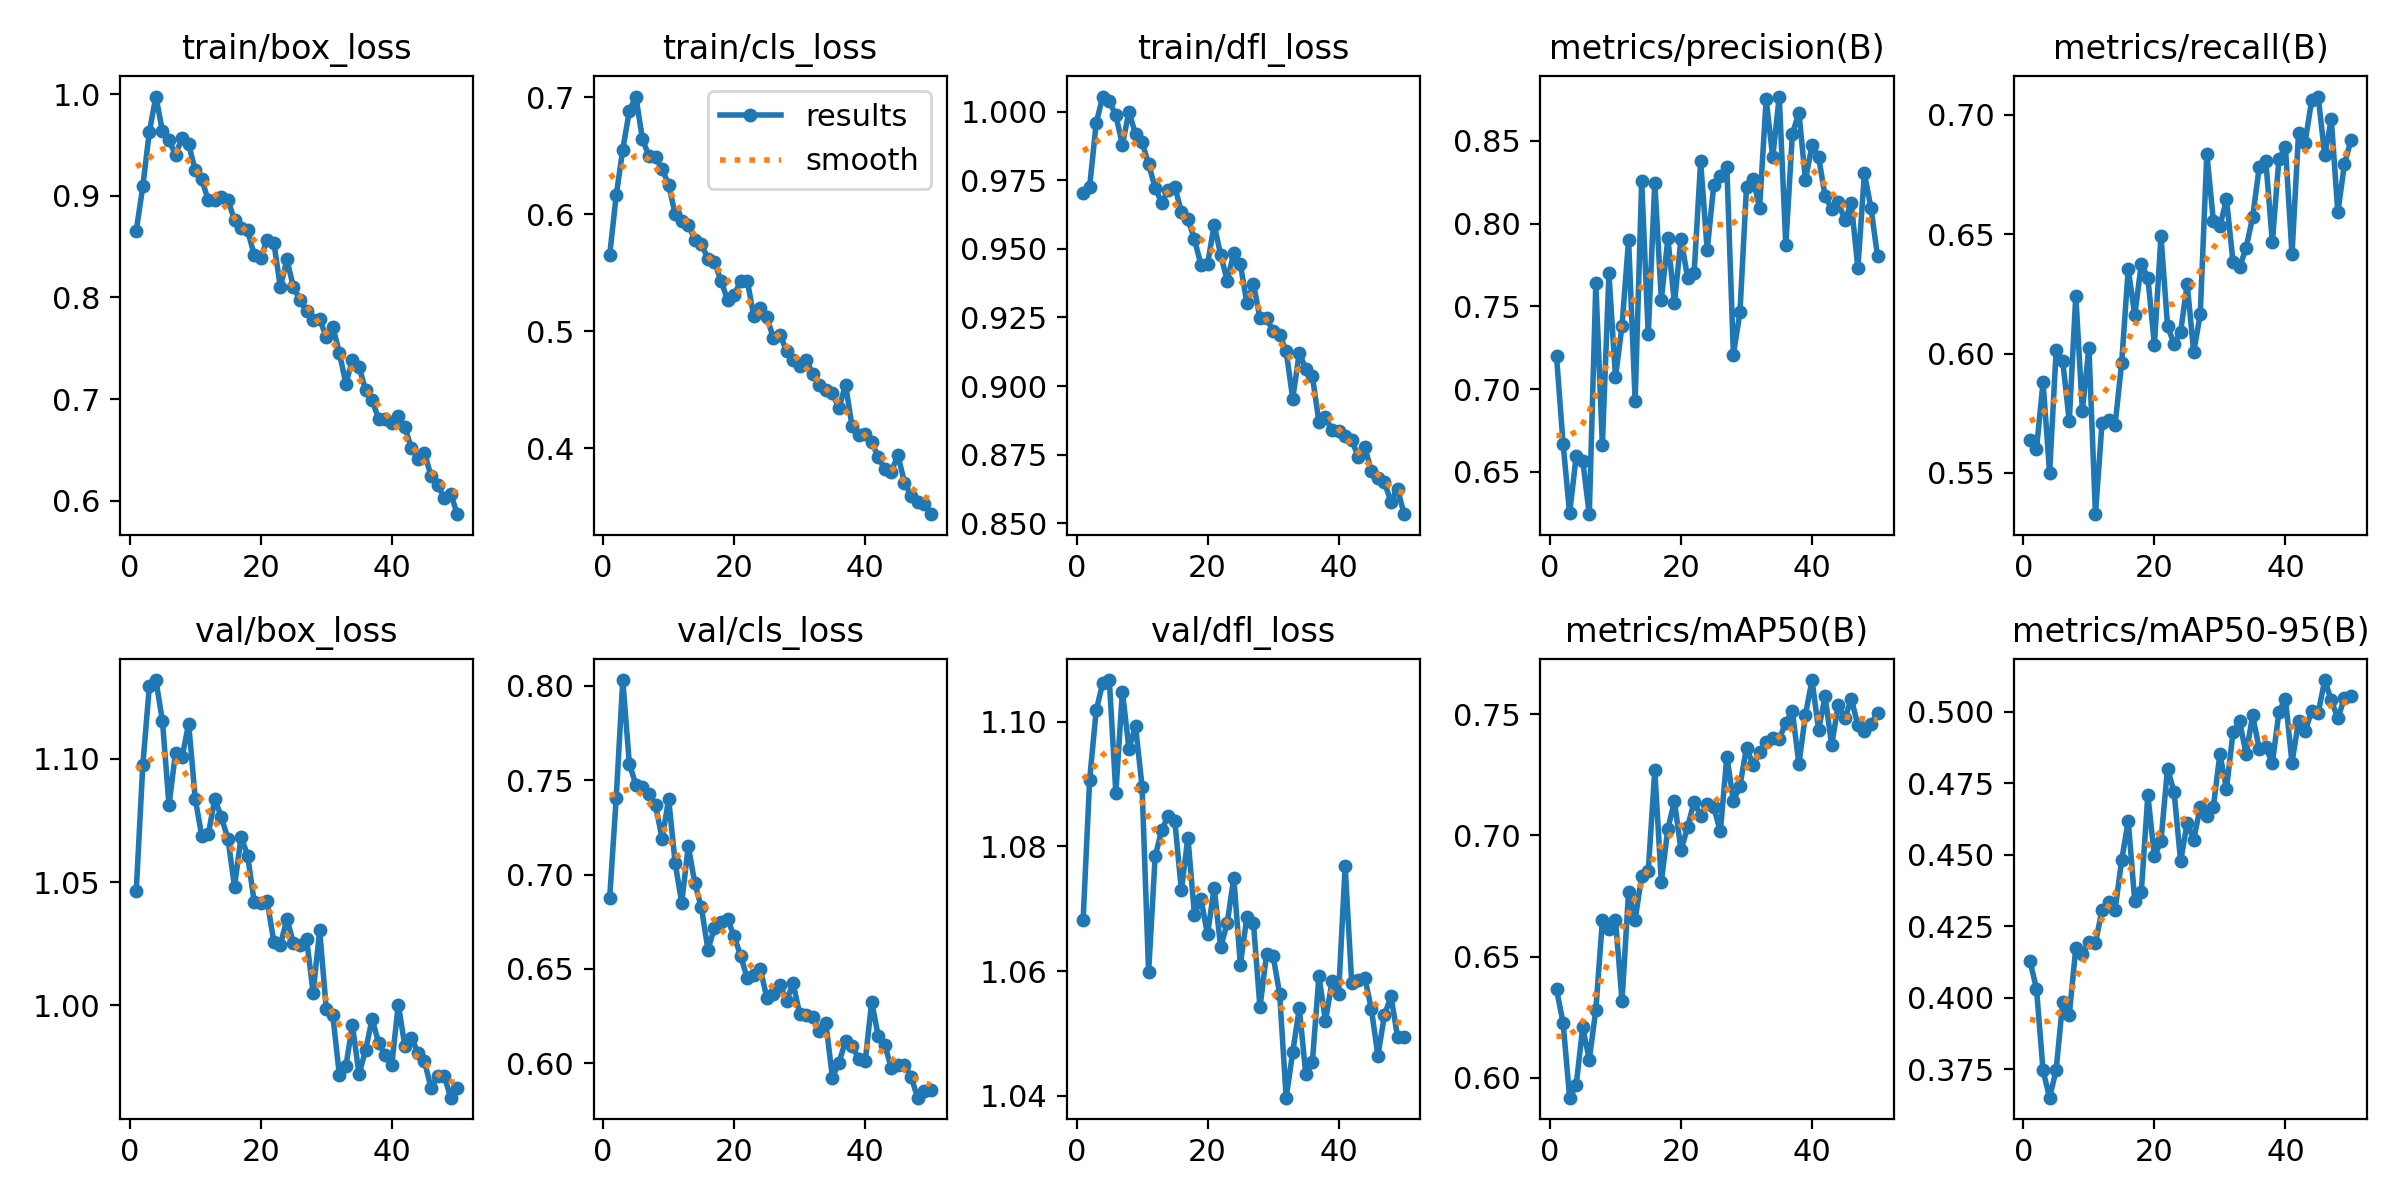

In [7]:
import os
import glob
from IPython.display import Image, display

# Base directory for training runs
runs_dir = r"C:\Users\Ayan\Desktop\YOLO THESIS PROJECT\Self-Driving Car Obstacles Yolo attempt kitti\runs\detect"

# Find the latest training run folder matching '50epochs*'
latest_run_dir = max(glob.glob(os.path.join(runs_dir, '50epochs*')), key=os.path.getctime)

# Path to the results plot
results_plot_path = os.path.join(latest_run_dir, 'results.png')

# Display the image
display(Image(filename=results_plot_path))


In [8]:
# You can also run validation after training
model = YOLO(r"C:\Users\Ayan\Desktop\YOLO THESIS PROJECT\Self-Driving Car Obstacles Yolo attempt kitti\runs\detect\50epochs\weights\best.pt")
results = model.val()

# Display key validation metrics in a human-readable format
print("\nValidation Metrics:")
print(f"  mAP50-95: {results.box.map:.4f}")
print(f"  mAP50: {results.box.map50:.4f}")
print(f"  Precision: {results.box.p.mean():.4f}")
print(f"  Recall: {results.box.r.mean():.4f}")

# Print metrics per class if available
if results.box.ap_class_index is not None and results.box.ap is not None:
    print("\nMetrics per Class:")
    for i, class_index in enumerate(results.box.ap_class_index):
        class_name = model.names[class_index]
        print(f"  Class '{class_name}' (ID {class_index}):")
        print(f"    AP50-95: {results.box.ap[i]:.4f}")
        print(f"    AP50: {results.box.ap50[i]:.4f}")
        print(f"    Precision: {results.box.p[i]:.4f}")
        print(f"    Recall: {results.box.r[i]:.4f}")

Ultralytics 8.3.253  Python-3.12.0 torch-2.5.1+cu121 CUDA:0 (NVIDIA GeForce RTX 4050 Laptop GPU, 6140MiB)
Model summary (fused): 92 layers, 25,844,392 parameters, 0 gradients, 78.7 GFLOPs
val: Fast image access  (ping: 0.00.0 ms, read: 710.8154.2 MB/s, size: 53.8 KB)
val: Scanning C:\Users\Ayan\Desktop\YOLO THESIS PROJECT\Self-Driving Car Obstacles Yolo attempt kitti\kitti\val\labels.cache... 191 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 191/191  0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 12/12 6.4it/s 1.9s0.1s
                   all        191       1073      0.814      0.684      0.757      0.509
                   car        171        758      0.899      0.858      0.916      0.699
                   van         50         64      0.835       0.63      0.731      0.561
                 truck         27         27      0.803      0.926       0.89       0.66
            pedestrian         54        132   

In [16]:
from ultralytics import YOLO

# Load YOLOv8 medium model
model = YOLO("yolo12m.pt") # if the file is not present, it will download automatically

In [17]:
# Train the model on the dataset
# 'data' specifies the path to your dataset.yaml file
# 'epochs' sets the number of training epochs
# 'imgsz' sets the image size
from ultralytics import YOLO


results = model.train(
    data='data.yaml',
    epochs=30,           # Train 30 more epochs
    imgsz=640,           # Smaller for speed
    batch=6,
    device=0,
    lr0=0.000001,          # Low learning rate
    patience=20,
    name='30epochs'
)

print("Training continued successfully!")

New https://pypi.org/project/ultralytics/8.4.3 available  Update with 'pip install -U ultralytics'
Ultralytics 8.3.253  Python-3.12.0 torch-2.5.1+cu121 CUDA:0 (NVIDIA GeForce RTX 4050 Laptop GPU, 6140MiB)
engine\trainer: agnostic_nms=False, amp=True, augment=False, auto_augment=randaugment, batch=6, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=30, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=1e-06, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo12m.pt, momentum=0.937, mosaic=1.0, multi_scale=False, name=30epochs, nbs=64, nms=False, opset=Non

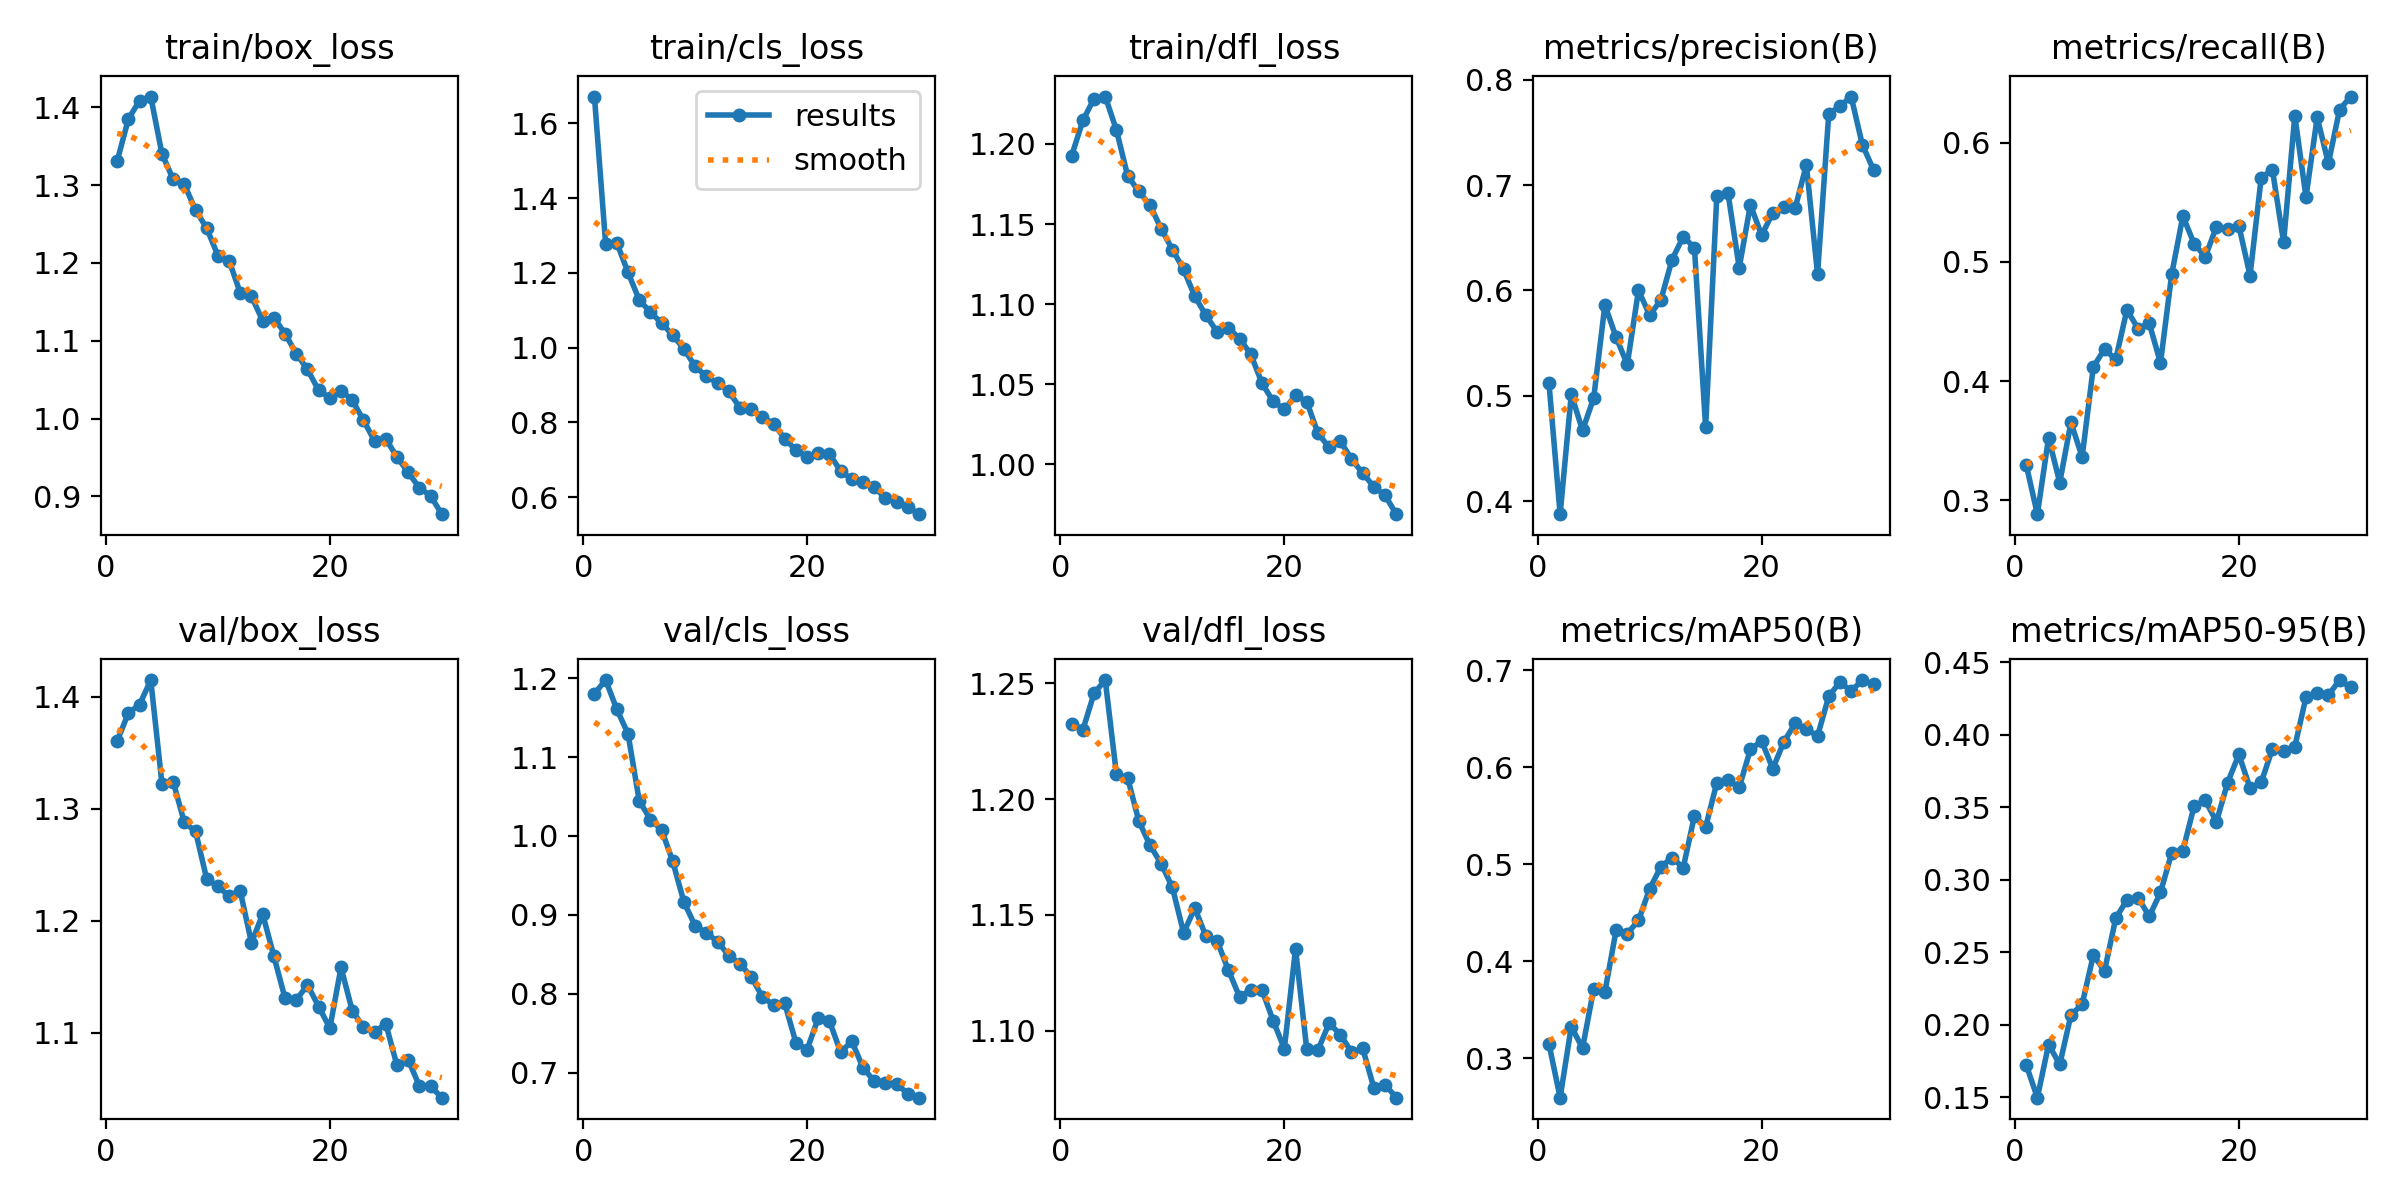

In [18]:
import os
import glob
from IPython.display import Image, display

# Base directory for training runs
runs_dir = r"C:\Users\Ayan\Desktop\YOLO THESIS PROJECT\Self-Driving Car Obstacles Yolo attempt kitti\runs\detect"

# Find the latest training run folder matching '50epochs*'
latest_run_dir = max(glob.glob(os.path.join(runs_dir, '30epochs*')), key=os.path.getctime)

# Path to the results plot
results_plot_path = os.path.join(latest_run_dir, 'results.png')

# Display the image
display(Image(filename=results_plot_path))


In [19]:
# You can also run validation after training
model = YOLO(r"C:\Users\Ayan\Desktop\YOLO THESIS PROJECT\Self-Driving Car Obstacles Yolo attempt kitti\runs\detect\30epochs\weights\best.pt")
results = model.val()

# Display key validation metrics in a human-readable format
print("\nValidation Metrics:")
print(f"  mAP50-95: {results.box.map:.4f}")
print(f"  mAP50: {results.box.map50:.4f}")
print(f"  Precision: {results.box.p.mean():.4f}")
print(f"  Recall: {results.box.r.mean():.4f}")

# Print metrics per class if available
if results.box.ap_class_index is not None and results.box.ap is not None:
    print("\nMetrics per Class:")
    for i, class_index in enumerate(results.box.ap_class_index):
        class_name = model.names[class_index]
        print(f"  Class '{class_name}' (ID {class_index}):")
        print(f"    AP50-95: {results.box.ap[i]:.4f}")
        print(f"    AP50: {results.box.ap50[i]:.4f}")
        print(f"    Precision: {results.box.p[i]:.4f}")
        print(f"    Recall: {results.box.r[i]:.4f}")

Ultralytics 8.3.253  Python-3.12.0 torch-2.5.1+cu121 CUDA:0 (NVIDIA GeForce RTX 4050 Laptop GPU, 6140MiB)
YOLOv12m summary (fused): 169 layers, 20,111,080 parameters, 0 gradients, 67.1 GFLOPs
val: Fast image access  (ping: 0.00.0 ms, read: 713.1140.1 MB/s, size: 53.8 KB)
val: Scanning C:\Users\Ayan\Desktop\YOLO THESIS PROJECT\Self-Driving Car Obstacles Yolo attempt kitti\kitti\val\labels.cache... 191 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 191/191  0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 12/12 6.2it/s 1.9s0.2s
                   all        191       1073      0.742      0.624      0.689      0.438
                   car        171        758      0.821      0.864      0.912      0.672
                   van         50         64       0.65      0.594      0.659      0.489
                 truck         27         27       0.83      0.815      0.879      0.657
            pedestrian         54        13

In [20]:
from ultralytics import YOLO

# Load YOLOv8 medium model
model = YOLO(r"C:\Users\Ayan\Desktop\YOLO THESIS PROJECT\Self-Driving Car Obstacles Yolo attempt kitti\runs\detect\30epochs\weights\best.pt") # if the file is not present, it will download automatically

In [22]:
# Train the model on the dataset
# 'data' specifies the path to your dataset.yaml file
# 'epochs' sets the number of training epochs
# 'imgsz' sets the image size
from ultralytics import YOLO


results = model.train(
    data='data.yaml',
    epochs=50,           # Train 30 more epochs
    imgsz=640,           # Smaller for speed
    batch=6,
    device=0,
    lr0=0.000001,          # Low learning rate
    patience=20,
    name='50epochs'
)

print("Training continued successfully!")

New https://pypi.org/project/ultralytics/8.4.3 available  Update with 'pip install -U ultralytics'
Ultralytics 8.3.253  Python-3.12.0 torch-2.5.1+cu121 CUDA:0 (NVIDIA GeForce RTX 4050 Laptop GPU, 6140MiB)
engine\trainer: agnostic_nms=False, amp=True, augment=False, auto_augment=randaugment, batch=6, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=1e-06, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=C:\Users\Ayan\Desktop\YOLO THESIS PROJECT\Self-Driving Car Obstacles Yolo attempt kitti\runs\detect\30

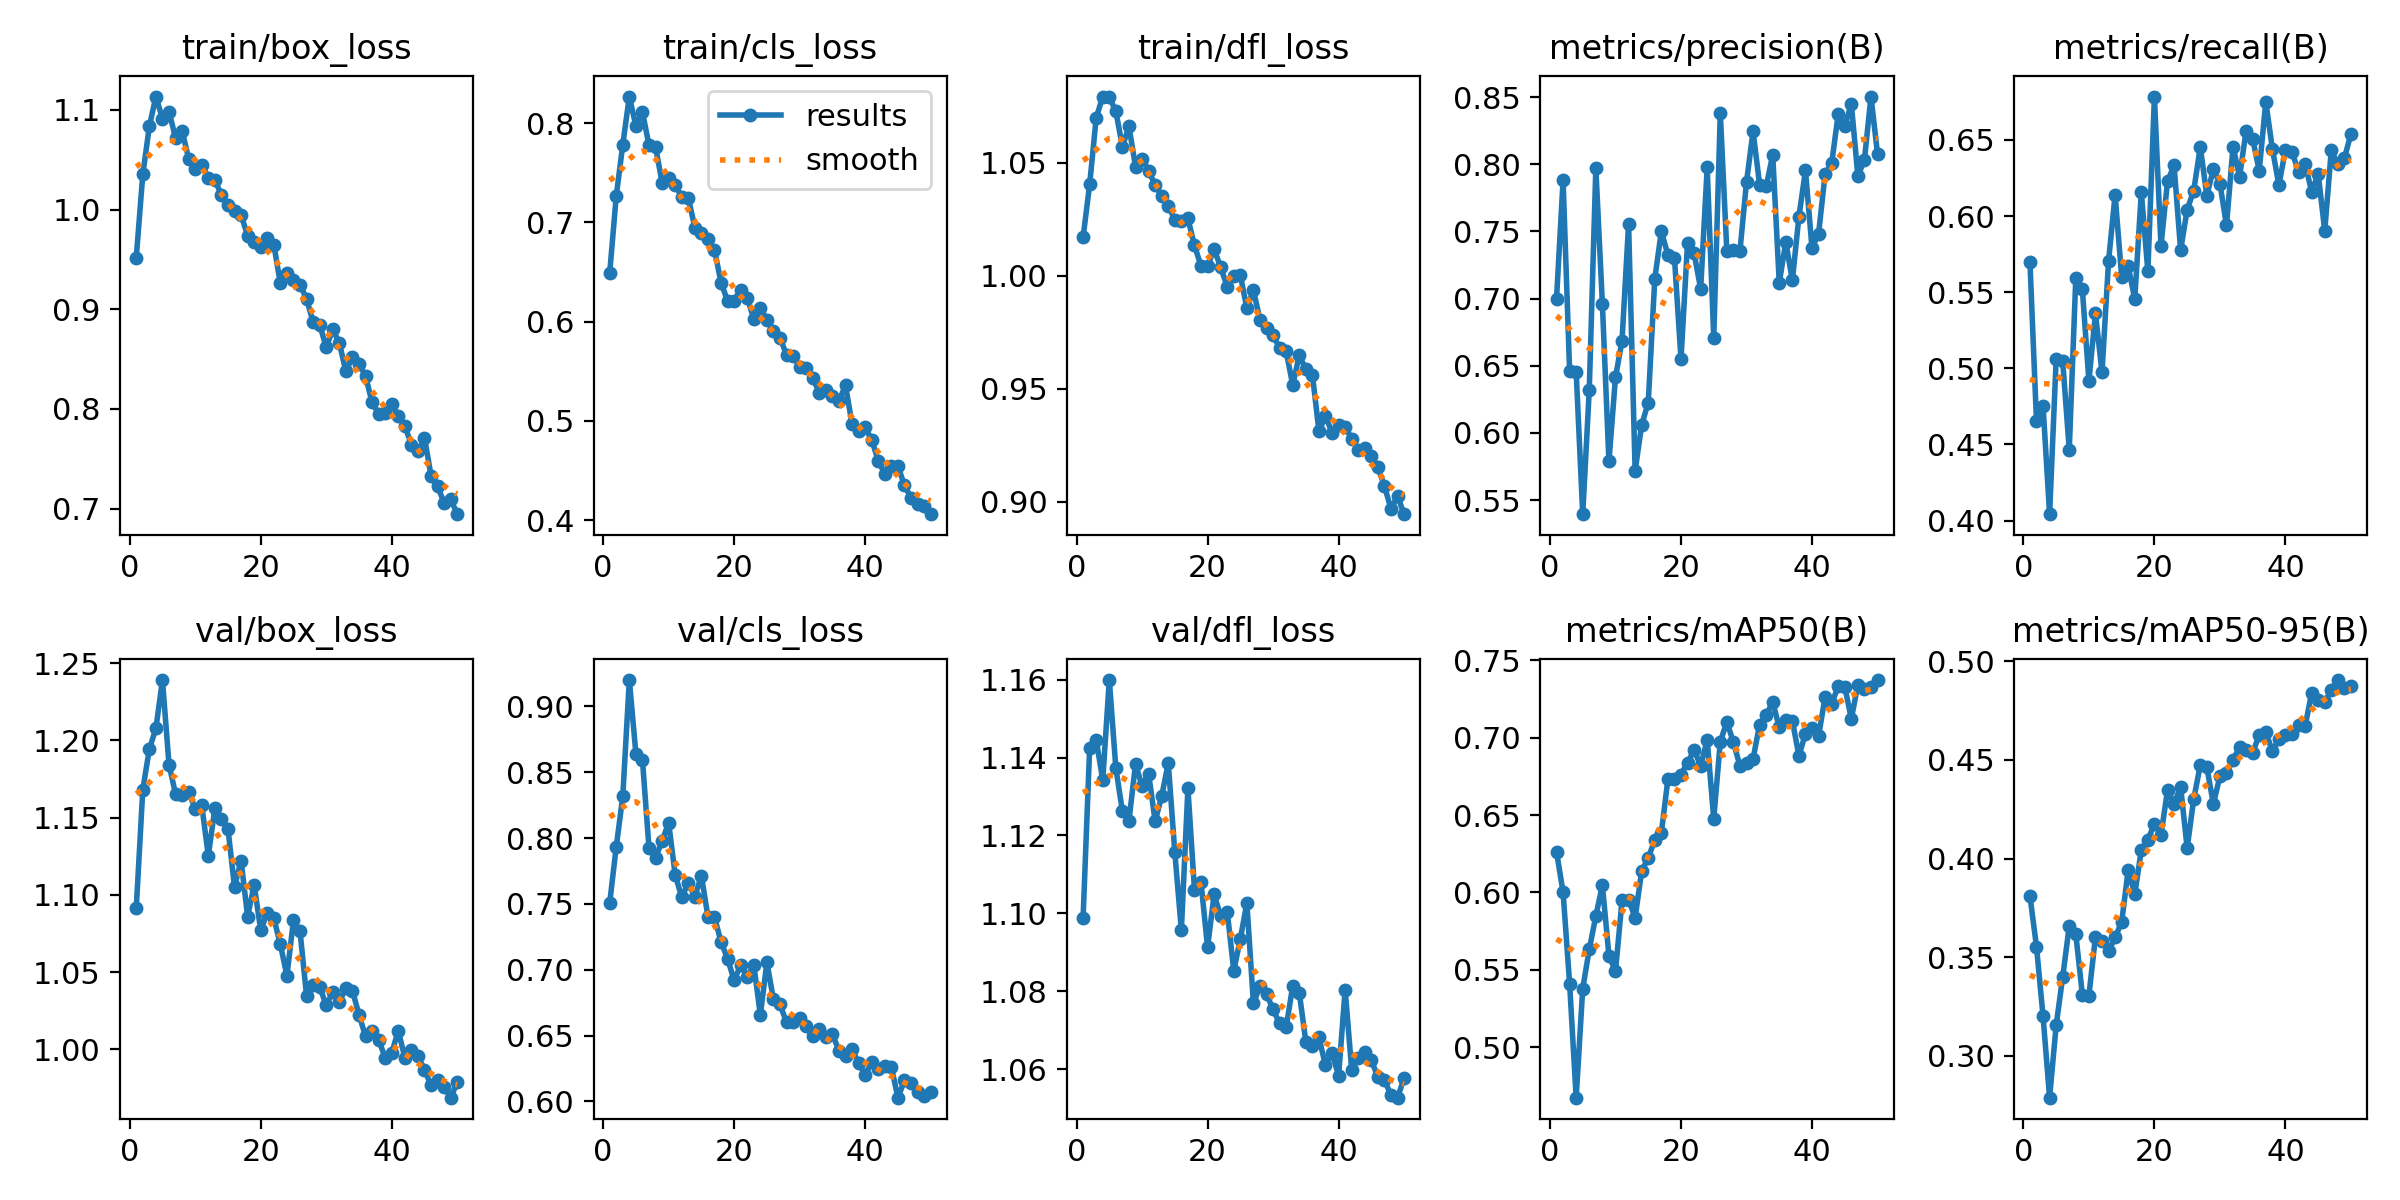

In [23]:
import os
import glob
from IPython.display import Image, display

# Base directory for training runs
runs_dir = r"C:\Users\Ayan\Desktop\YOLO THESIS PROJECT\Self-Driving Car Obstacles Yolo attempt kitti\runs\detect"

# Find the latest training run folder matching '50epochs*'
latest_run_dir = max(glob.glob(os.path.join(runs_dir, '50epochs*')), key=os.path.getctime)

# Path to the results plot
results_plot_path = os.path.join(latest_run_dir, 'results.png')

# Display the image
display(Image(filename=results_plot_path))


In [24]:
# You can also run validation after training
model = YOLO(r"C:\Users\Ayan\Desktop\YOLO THESIS PROJECT\Self-Driving Car Obstacles Yolo attempt kitti\runs\detect\50epochs\weights\best.pt")
results = model.val()

# Display key validation metrics in a human-readable format
print("\nValidation Metrics:")
print(f"  mAP50-95: {results.box.map:.4f}")
print(f"  mAP50: {results.box.map50:.4f}")
print(f"  Precision: {results.box.p.mean():.4f}")
print(f"  Recall: {results.box.r.mean():.4f}")

# Print metrics per class if available
if results.box.ap_class_index is not None and results.box.ap is not None:
    print("\nMetrics per Class:")
    for i, class_index in enumerate(results.box.ap_class_index):
        class_name = model.names[class_index]
        print(f"  Class '{class_name}' (ID {class_index}):")
        print(f"    AP50-95: {results.box.ap[i]:.4f}")
        print(f"    AP50: {results.box.ap50[i]:.4f}")
        print(f"    Precision: {results.box.p[i]:.4f}")
        print(f"    Recall: {results.box.r[i]:.4f}")

Ultralytics 8.3.253  Python-3.12.0 torch-2.5.1+cu121 CUDA:0 (NVIDIA GeForce RTX 4050 Laptop GPU, 6140MiB)
YOLOv12m summary (fused): 169 layers, 20,111,080 parameters, 0 gradients, 67.1 GFLOPs
val: Fast image access  (ping: 0.00.0 ms, read: 678.2110.0 MB/s, size: 53.8 KB)
val: Scanning C:\Users\Ayan\Desktop\YOLO THESIS PROJECT\Self-Driving Car Obstacles Yolo attempt kitti\kitti\val\labels.cache... 191 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 191/191  0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 12/12 6.2it/s 1.9s0.2s
                   all        191       1073      0.826       0.62      0.731      0.492
                   car        171        758      0.903      0.849       0.92      0.703
                   van         50         64      0.846      0.688      0.745       0.58
                 truck         27         27      0.856      0.878      0.936      0.713
            pedestrian         54        13